## 3.3 Logistic Regression

**Wat is logistic regression?**
Logistic regression is een classificatiemodel. Het model berekent eerst een gewogen som van de features:

$$z = b_0 + b_1 x_1 + b_2 x_2 + \dots + b_n x_n$$

Deze som zet het model met de sigmoïdefunctie om naar een kans tussen 0 en 1:

$$P(\text{stroke} = 1) = \frac{1}{1 + e^{-z}}$$

Is de kans groter dan de threshold (standaard 0,5), dan voorspelt het model een herseninfarct.

**Waarom dit model?**
- Het is een eenvoudig en snel model, en daarom een goede baseline om andere modellen mee te vergelijken.
- De coëfficiënten zijn goed te interpreteren: een positieve coëfficiënt betekent dat de feature de kans op een herseninfarct verhoogt. Dat is belangrijk voor artsen, die willen begrijpen waarom het model een patiënt als risicopatiënt aanwijst.

**Data inladen**
We laden de opgeschoonde data in via `StrokeData`. Deze voert dezelfde opschoonstappen uit als in paragraaf 1.6 van de EDA.

In [10]:
"""Logistic regression voor de Kaggle-competitie Predicting stroke."""
import sys

sys.path.append("..")  # zodat de map src gevonden wordt

from src.preprocessing import NUMERIC_COLS, StrokeData

data = StrokeData()
X, y = data.get_xy()
X_test = data.get_test()

print(X.shape, y.shape, X_test.shape)
print("Percentage stroke:", round(y.mean() * 100, 2))

(33544, 15) (33544,) (8388, 15)
Percentage stroke: 1.54


De trainset bevat 33.544 patiënten en 15 features. Slechts 1,54% heeft een herseninfarct gehad.

--------
### Baseline

We beginnen met een logistic regression met standaardinstellingen. Dit dient als baseline: elk volgend model moet beter scoren.

- Alleen de numerieke features worden gestandaardiseerd (zie paragraaf 1.7). De binaire features blijven 0/1.
- De scaler zit in een `Pipeline`, zodat hij per fold alleen op de trainingsdata wordt gefit. Zo voorkomen we data leakage.
- We evalueren met 5-fold `StratifiedKFold`: elke fold bevat hetzelfde percentage herseninfarcten (1,54%).

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, precision_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

preprocessor = ColumnTransformer(
    [("scale", StandardScaler(), NUMERIC_COLS)],
    remainder="passthrough",  # binaire kolommen blijven 0/1
)

baseline = Pipeline([
    ("pre", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": "f1",
}

scores = cross_validate(baseline, X, y, cv=cv, scoring=scoring)
for metric in scoring:
    print(f"{metric}: {scores[f'test_{metric}'].mean():.3f}")

accuracy: 0.985
precision: 0.000
recall: 0.000
f1: 0.000


**Observatie:** de baseline voorspelt voor geen enkele patiënt een herseninfarct. De accuracy is 0,985, maar dat is precies het percentage patiënten zonder herseninfarct. De recall en F1-score zijn 0: het model vindt geen enkele risicopatiënt en is daarmee voor een arts onbruikbaar. Door de sterke onbalans is het voor het model 'voordeliger' om de kleine klasse te negeren.

--------
### Class weights

Om de onbalans op te vangen geven we de klassen een gewicht met `class_weight="balanced"`. Een fout bij een patiënt met een herseninfarct telt dan zwaarder mee in de loss dan een fout bij een patiënt zonder. Het gewicht is omgekeerd evenredig met de klassegrootte: een patiënt met een herseninfarct telt ongeveer 32 keer zo zwaar.

In [12]:
balanced = Pipeline([
    ("pre", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=42,
                               class_weight="balanced")),
])

scores = cross_validate(balanced, X, y, cv=cv, scoring=scoring)
for metric in scoring:
    print(f"{metric}: {scores[f'test_{metric}'].mean():.3f}")

accuracy: 0.748
precision: 0.047
recall: 0.803
f1: 0.089


**Observatie:** de recall stijgt van 0 naar 0,803: het model vindt nu 80% van de patiënten met een herseninfarct. De precision is echter slechts 0,047: van elke 100 patiënten die het model als risicopatiënt aanwijst, heeft maar ongeveer 5 daadwerkelijk een herseninfarct. De F1-score (0,089) is beter dan de baseline, maar nog laag. Het model is doorgeslagen naar de andere kant: het geeft te veel valse alarmen.

--------
### Confusion matrix

De scores hierboven zijn gemiddelden over de folds. Met een confusion matrix zien we per patiënt wat het model voorspelt:

- **TN (true negative):** geen herseninfarct, correct voorspeld
- **FP (false positive):** geen herseninfarct, maar wel als risicopatiënt aangewezen (vals alarm)
- **FN (false negative):** wel een herseninfarct, maar gemist door het model
- **TP (true positive):** herseninfarct, correct voorspeld

We gebruiken `cross_val_predict`: elke patiënt krijgt een voorspelling van het model dat níét op die patiënt is getraind. Zo bevat de matrix alle 33.544 patiënten zonder dat het model de antwoorden al heeft gezien.

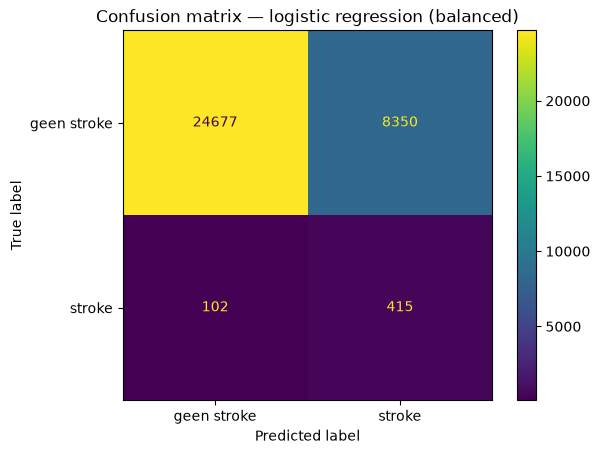

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict
import matplotlib.pyplot as plt

y_pred = cross_val_predict(balanced, X, y, cv=cv)

ConfusionMatrixDisplay.from_predictions(
    y, y_pred, display_labels=["geen stroke", "stroke"]
)
plt.title("Confusion matrix — logistic regression (balanced)")
plt.show()

**Observatie:** het model vindt 415 van de 517 patiënten met een herseninfarct (TP) en mist er 102 (FN). Daar staan 8.350 valse alarmen tegenover (FP): patiënten zonder herseninfarct die als risicopatiënt worden aangewezen. Voor een arts betekent dit dat ongeveer 95 van elke 100 waarschuwingen onterecht zijn. Het model is gevoelig, maar niet specifiek genoeg.

------
### Threshold

Logistic regression voorspelt een kans. Standaard wordt een patiënt als risicopatiënt aangewezen als deze kans ≥ 0,5 is. Deze grens (de threshold) kunnen we zelf kiezen:

- Een **hogere** threshold geeft minder valse alarmen (hogere precision), maar het model mist meer patiënten met een herseninfarct (lagere recall).
- Een **lagere** threshold werkt andersom.

We bekijken de precision, recall en F1-score bij verschillende thresholds.

In [14]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, precision_score, recall_score

y_proba = cross_val_predict(balanced, X, y, cv=cv, method="predict_proba")[:, 1]

rows = []
for threshold in np.arange(0.5, 1.0, 0.05):
    y_pred_t = (y_proba >= threshold).astype(int)
    rows.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(y, y_pred_t, zero_division=0),
        "recall": recall_score(y, y_pred_t),
        "f1": f1_score(y, y_pred_t),
    })

pd.DataFrame(rows).round(3)

,threshold,precision,recall,f1
0,0.50,0.047,0.803,0.089
1,0.55,0.052,0.776,0.098
2,0.60,0.056,0.729,0.105
3,0.65,0.062,0.692,0.114
4,0.70,0.070,0.646,0.127
5,0.75,0.076,0.559,0.135
6,0.80,0.085,0.420,0.141
7,0.85,0.097,0.282,0.145
8,0.90,0.103,0.106,0.105
9,0.95,0.127,0.014,0.024


**Observatie:** hoe hoger de threshold, hoe hoger de precision en hoe lager de recall. De hoogste F1-score (0,145) ligt bij een threshold van 0,85, maar daar vindt het model nog maar 28% van de patiënten met een herseninfarct. Bij 0,80 is de F1-score bijna even hoog (0,141) met een recall van 42%. Zelfs bij de beste threshold blijft de precision onder de 10%. Het probleem zit dus niet alleen in de threshold: veel patiënten met dezelfde risicofactoren (hoge leeftijd, hoge bloeddruk) krijgen géén herseninfarct, waardoor het model de klassen moeilijk kan scheiden.

### Threshold kiezen zonder data leakage

In de tabel hierboven hebben we de threshold gekozen op basis van dezelfde voorspellingen waarop we de score meten. Daardoor is de score te optimistisch. Met `TunedThresholdClassifierCV` wordt de threshold binnen elke fold alleen op de trainingsdata gekozen en daarna getest op data die het model niet heeft gezien.

In [15]:
from sklearn.model_selection import TunedThresholdClassifierCV

tuned = TunedThresholdClassifierCV(balanced, scoring="f1", cv=5, random_state=42)

scores = cross_validate(tuned, X, y, cv=cv, scoring=scoring, return_estimator=True)
for metric in scoring:
    print(f"{metric}: {scores[f'test_{metric}'].mean():.3f}")

print("Gekozen thresholds:", [round(m.best_threshold_, 2) for m in scores["estimator"]])


accuracy: 0.924
precision: 0.087
recall: 0.412
f1: 0.143
Gekozen thresholds: [np.float64(0.8), np.float64(0.81), np.float64(0.8), np.float64(0.81), np.float64(0.81)]


**Observatie:** met een eerlijk gekozen threshold is de F1-score 0,143. Dit ligt dicht bij de 0,145 uit de tabel hierboven, dus die schatting was nauwelijks te optimistisch. In alle vijf de folds wordt een threshold van 0,80 of 0,81 gekozen: de keuze is stabiel en niet afhankelijk van toeval. Het model vindt nu 41% van de patiënten met een herseninfarct, en ongeveer 9 van elke 100 waarschuwingen zijn terecht. Ten opzichte van `class_weight="balanced"` met threshold 0,5 levert dit een duidelijk betere balans tussen precision en recall op.

------
### Hyperparameter tuning

Logistic regression gebruikt standaard L2-regularisatie. De sterkte hiervan bepalen we met de hyperparameter `C`. Een kleine `C` betekent sterke regularisatie (een eenvoudiger model met kleinere coëfficiënten), een grote `C` betekent zwakke regularisatie. We zoeken met `GridSearchCV` de beste waarde, waarbij voor elke `C` ook de threshold opnieuw wordt gekozen.

In [16]:
from sklearn.model_selection import GridSearchCV

param_grid = {"estimator__clf__C": [0.001, 0.01, 0.1, 1, 10]}

grid = GridSearchCV(tuned, param_grid, scoring="f1", cv=cv, n_jobs=-1)
grid.fit(X, y)

results = pd.DataFrame(grid.cv_results_)[
    ["param_estimator__clf__C", "mean_test_score", "std_test_score"]
]
results.columns = ["C", "f1_gemiddeld", "f1_std"]
print(results.round(3))
print("Beste C:", grid.best_params_["estimator__clf__C"])

        C  f1_gemiddeld  f1_std
0   0.001         0.137   0.010
1   0.010         0.141   0.008
2   0.100         0.142   0.009
3   1.000         0.143   0.008
4  10.000         0.143   0.008
Beste C: 1


**Observatie:** de F1-score varieert tussen 0,137 en 0,143. Dit verschil (0,006) is kleiner dan de standaardafwijking tussen de folds (0,008–0,010) en dus niet betekenisvol. De sterkte van de regularisatie heeft nauwelijks invloed. Dit is te verklaren: met 33.544 patiënten en slechts 15 features heeft een lineair model weinig kans om te overfitten. We houden de standaardwaarde `C = 1` aan.

---------
### Interpretatie van het model

Een voordeel van logistic regression is dat de coëfficiënten te interpreteren zijn. We trainen het model op de volledige trainset en bekijken de odds ratio per feature: $e^{b}$.

- **Odds ratio > 1:** de feature verhoogt de kans op een herseninfarct.
- **Odds ratio < 1:** de feature verlaagt de kans.
- Voor de gestandaardiseerde features (`age`, `avg_glucose_level`, `bmi`) geldt de odds ratio per standaardafwijking. Voor de binaire features geldt deze ten opzichte van de weggelaten dummy (zie paragraaf 1.6).

In [17]:
import numpy as np

final_model = Pipeline([
    ("pre", ColumnTransformer(
        [("scale", StandardScaler(), NUMERIC_COLS)],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )),
    ("clf", LogisticRegression(max_iter=1000, random_state=42,
                               class_weight="balanced")),
])
final_model.fit(X, y)

coefs = pd.DataFrame({
    "feature": final_model.named_steps["pre"].get_feature_names_out(),
    "coëfficiënt": final_model.named_steps["clf"].coef_[0],
})
coefs["odds_ratio"] = np.exp(coefs["coëfficiënt"])
coefs.sort_values("coëfficiënt", key=abs, ascending=False).round(2)

,feature,coëfficiënt,odds_ratio
0,age,1.72,5.58
4,heart_disease,0.62,1.86
3,hypertension,0.59,1.80
14,smoking_status_smokes,0.51,1.66
7,work_type_Govt_job,-0.40,0.67
10,work_type_children,-0.36,0.70
8,work_type_Private,-0.34,0.71
13,smoking_status_never smoked,0.23,1.26
9,work_type_Self-employed,-0.20,0.81
12,smoking_status_formerly smoked,0.20,1.22


**Observatie:**
- De drie sterkste voorspellers zijn `age`, `heart_disease` en `hypertension`, dezelfde features als in de EDA. Een standaardafwijking hogere leeftijd (ongeveer 22 jaar) vergroot de odds op een herseninfarct met een factor 5,6. Een hartziekte of hoge bloeddruk verdubbelt de odds ongeveer.
- `ever_married_Yes` heeft in de EDA een duidelijk verband met `stroke`, maar in het model is de odds ratio 0,92. Het model corrigeert voor leeftijd, waardoor dit verband verdwijnt. Dit bevestigt dat leeftijd een confounder is (paragraaf 1.4.4).
- `avg_glucose_level` heeft een kleiner effect (1,18) dan de EDA deed vermoeden. Het effect zit vooral in de hoge waarden (de tweede piek), terwijl logistic regression alleen een lineair verband kan leggen.
- De coëfficiënten van `work_type` zijn niet goed te interpreteren: ze zijn relatief ten opzichte van `work_type_Never_worked`, een zeer kleine groep zonder herseninfarcten.
- Alle rookcategorieën hebben een odds ratio > 1, omdat ze vergeleken worden met de categorie Unknown, waarin veel kinderen zitten. Dit betekent niet dat niet-roken het risico verhoogt.

**Voor de arts:** het model baseert zijn voorspellingen vooral op bekende medische risicofactoren. Dit maakt de voorspellingen goed uitlegbaar.

-----
### Kaggle-submission

Het uiteindelijke model is logistic regression met `class_weight="balanced"`, `C = 1` en een threshold die met `TunedThresholdClassifierCV` wordt gekozen. We trainen dit model op de volledige trainset en voorspellen de testset.

In [18]:
from pathlib import Path

final_tuned = TunedThresholdClassifierCV(balanced, scoring="f1", cv=5, random_state=42)
final_tuned.fit(X, y)

test_pred = final_tuned.predict(X_test)

submission = pd.DataFrame({"id": data.test_ids, "stroke": test_pred})
Path("../submissions").mkdir(exist_ok=True)
submission.to_csv("../submissions/logreg.csv", index=False)

print("Gekozen threshold:", round(final_tuned.best_threshold_, 2))
print("Aantal voorspelde herseninfarcten:", test_pred.sum(),
      f"({test_pred.mean() * 100:.2f}%)")

Gekozen threshold: 0.8
Aantal voorspelde herseninfarcten: 664 (7.92%)


**Observatie:** op de volledige trainset wordt opnieuw een threshold van 0,80 gekozen, gelijk aan de cross-validatie. Het model wijst 664 van de 8.388 testpatiënten (7,92%) aan als risicopatiënt. Als de testset hetzelfde percentage herseninfarcten heeft als de trainset (1,54%, ongeveer 129 patiënten), zijn de meeste waarschuwingen vals alarm. Dit komt overeen met de precision van ongeveer 9% uit de cross-validatie.

### Conclusie logistic regression

| Model | Precision | Recall | F1-score |
|---|---|---|---|
| Baseline | 0,000 | 0,000 | 0,000 |
| `class_weight="balanced"` (threshold 0,5) | 0,047 | 0,803 | 0,089 |
| `class_weight="balanced"` + getunede threshold | 0,087 | 0,412 | **0,143** |

- Zonder aanpassingen negeert logistic regression de kleine klasse volledig. Class weights en een getunede threshold zijn allebei nodig voor een bruikbaar model.
- Het beste model vindt 41% van de patiënten met een herseninfarct. Ongeveer 9 van elke 100 waarschuwingen zijn terecht.
- De regularisatiesterkte `C` heeft nauwelijks invloed, omdat een lineair model met 15 features op 33.544 patiënten weinig overfit.
- **Sterk punt:** het model is goed uitlegbaar. De belangrijkste voorspellers (leeftijd, hartziekte en hoge bloeddruk) zijn bekende medische risicofactoren.
- **Zwak punt:** het model kan alleen lineaire verbanden leggen. Het niet-lineaire effect van `avg_glucose_level` (de tweede piek) wordt daardoor gemist. Modellen op basis van decision trees kunnen dit wel oppikken (zie paragraaf 3.6).